# Fig. 2e-h: Behavior of the fitted models

[AI generated summary] Behavior of the standard RL, inferential RL and foraging models simulated with the parameters fitted to each monkey (100,000 trials), compared to the monkeys:
- **Fig. 2e,g**: probability of switching for the different reward histories (e: KA, g: PO).
- **Fig. 2f,h**: probability of choosing the high-payoff target and of switching across a block (f: KA, h: PO).

**How to run:** run all cells. Figures are saved in `figs/`.

**Results:** precomputed results are provided in `results/behav_modeling/fitting_no_cv` (see the README). To recompute them, run in this folder: `python run_model_fitting.py --no-cv` (fits on the full data, without cross-validation; several hours).

Source data of the plotted panels are exported to `source_data/` (see `popy/source_data.py`).

---
# Setup

In [1]:
# @title Imports
import pandas as pd
import matplotlib.pyplot as plt

from popy.plotting.plotting_tools import *
from popy.behavior_data_tools import *
from popy.config import RESULTS_PATH

In [2]:
import os
from popy.config import FIGS_PATH
os.makedirs(FIGS_PATH, exist_ok=True)  # the figure panels are saved here

In [3]:
agents_to_show = {
    'recording': 'recording',
    #'WSLS': 'WSLS',
    'Standard RL - stickiness': 'Standard RL',
    'Inferential RL - stickiness': 'Inferential RL',
    'Foraging': 'Foraging',
    #'HSMMAgent': 'HSMM',
}

In [4]:
def plot_hist_thingy(behav_original, title=None, paper_format=False):
    labels = [ f"- - -", f"o - -" , f"- o -", f"o o -", f"- - o", f"o - o", f"- o o", f"o o o"]

    if paper_format:
        fontsize = 8
        plt.rcParams.update({'font.size': fontsize})
        h, w = 2, 1.6  # height and width in cm 
        s = 4
        lw = 1.2
    else:
        plt.rcParams.update({'font.size': 12})
        h, w = 4, 6
        s = 10
        lw = 2

    fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(w, h), gridspec_kw={'height_ratios': [2, 1], 'hspace': 0})

    if title is not None:
        fig.suptitle(title)

    ax = ax1

    for i, (monkey, behav_data) in enumerate(behav_original.groupby('monkey')):
        behav = behav_data.copy()

        #balance for shifts (random undersampling majority class)
        '''n_switch = np.sum(behav['switch'])
        n_no_switch = len(behav) - n_switch
        n_minority = int(np.min([n_switch, n_no_switch]))
        behav = behav.groupby('switch').apply(lambda x: x.sample(n=n_minority, random_state=42)).reset_index(drop=True)'''

        # downsample each groups
        comb_counts = behav.groupby(['R_1', 'R_2', 'R_3']).size().reset_index(name='counts')
        min_count = comb_counts['counts'].min()  # Determine the minimum count among the combinations
        # Function to undersample each combination
        def undersample(group):
            return group.sample(n=min_count, random_state=42)
        behav = behav.groupby(['R_1', 'R_2', 'R_3']).apply(undersample).reset_index(drop=True)  # Apply undersampling

        all_trials_vector = []
        for (R_1, R_2, R_3), behav_temp in behav.groupby(['R_1', 'R_2', 'R_3']):
            all_trials_vector.append(behav_temp['switch'].mean())

        # Check if monkey name ends with _short to use dashed line
        if monkey.endswith('_short'):
            linestyle = 'dashed'
            monkey_base = monkey[:-6]  # Remove '_short' suffix
        else:
            linestyle = 'solid'
            monkey_base = monkey
            
        color = COLORS[monkey_base] if monkey_base in COLORS else 'grey'
        ax.plot(all_trials_vector, label=f'{monkey}',
                color=color, 
                alpha=.8,
                linestyle=linestyle,
                markerfacecolor=color if monkey_base in ['ka', 'po', 'yu_DCZ', 'yu_sham'] else 'white',
                marker='*' if monkey_base in ['ka', 'po', 'yu_DCZ', 'yu_sham'] else 'o',
                zorder=0 if monkey_base in ['ka', 'po', 'yu_DCZ', 'yu_sham'] else 10,
                markersize=s*2 if monkey_base in ['ka', 'po', 'yu_DCZ', 'yu_sham'] else s,
                linewidth=lw)# if not monkey in ['ka', 'po', 'yu_DCZ', 'yu_sham'] else lw*2, alpha=0.8)

    ax.axhline(0, color='black', linestyle='-', alpha=1, linewidth=1)

    ax.set_xticks(np.arange(len(labels)))
    ax.set_xticklabels(labels, rotation=90)

    ax.set_xlabel('')
    ax.set_ylim(-0.02, .7)
    ax.set_ylabel('Proba. switch')

    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.spines["bottom"].set_visible(False)

    # legend to the right
    ax.legend(loc='center left', bbox_to_anchor=(1, 0.5), ncol=1)

    ax = ax2
    # just a transparent axis
    ax.axis('off')

    '''ax = ax2
    for i, label in enumerate(labels):
        for j, marker in enumerate(label.split(' ')):        
            ax.scatter(i, j, marker='o' if marker == 'o' else 'x', c='tab:green' if marker == 'o' else 'tab:red')

    #ax.set_xticks([])

    ax.set_yticks([0,1,2])
    ax.set_yticklabels(['t-3', 't-2', 't-1'])
    ax.set_ylim(-1, 3)

    ax.set_ylabel('past trials')

    # make legend: o for rewarded, x for unrewarded
    ax.scatter([], [], color="tab:green", marker="o", label="Rewarded")
    ax.scatter([], [], color="tab:red", marker="x", label="Unrewarded")
    ax.legend(loc='lower center', bbox_to_anchor=(0.8, -0.5), ncol=1)

    ax.spines["right"].set_visible(False)
    ax.spines["top"].set_visible(False)
    ax.spines["bottom"].set_visible(False)'''

    if not paper_format:
        plt.tight_layout()

    return fig, (ax1, ax2)
  

---
# Fig. 2e-h

Processing monkey: ka
model
Foraging - abandoned bias                        100000
Standard RL - forgetting + stickiness            100000
Foraging - adaptive threshold                    100000
Foraging                                         100000
Standard RL                                      100000
Standard RL - stickiness                         100000
Inferential RL - stickiness + multiple alphas    100000
Foraging - abandoned bias + spatial bias         100000
HSMMAgent                                        100000
WSLS                                             100000
Standard RL - forgetting                         100000
Inferential RL                                   100000
Repeating agent                                  100000
Inferential RL - stickiness + spatial bias       100000
Foraging - no reset                              100000
Inferential RL - stickiness                      100000
recording                                         23860
Name: count, dtype: 

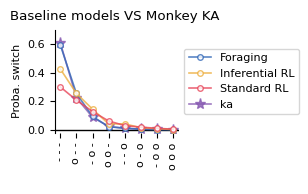

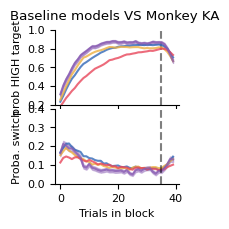

Processing monkey: po
model
Repeating agent                                  100000
Foraging - abandoned bias                        100000
Standard RL - stickiness                         100000
Foraging - adaptive threshold                    100000
Inferential RL - stickiness + multiple alphas    100000
Inferential RL - stickiness                      100000
Standard RL                                      100000
Foraging - abandoned bias + spatial bias         100000
HSMMAgent                                        100000
WSLS                                             100000
Foraging - no reset                              100000
Standard RL - forgetting                         100000
Foraging                                         100000
Inferential RL - stickiness + spatial bias       100000
Standard RL - forgetting + stickiness            100000
Inferential RL                                   100000
recording                                         15155
Name: count, dtype: 

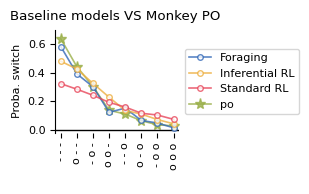

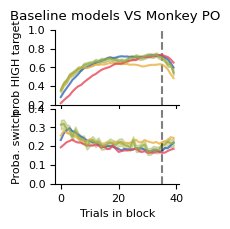

In [5]:
for monkey in ['ka', 'po']:#, 'yu_sham', 'yu_DCZ']:
    print(f'Processing monkey: {monkey}')
    behav = pd.read_pickle(os.path.join(RESULTS_PATH, 'behav_modeling', 'fitting_no_cv', f'simulation_behaviors_{monkey}.pkl'))

    # print num trials per model
    print(behav.model.value_counts())

    # remove n_target_touches column if exists
    if 'n_target_touches' in behav.columns:
        behav = behav.drop(columns=['n_target_touches'])
    # keep only models in agents_to_show.keys() and renaming them
    behav = behav[behav['model'].isin(agents_to_show.keys())].copy()
    behav['model'] = behav['model'].map(agents_to_show)
    # rename 'recording' to 'monkey'
    behav['model'] = behav['model'].replace({'recording': monkey})

    # Apply the function to create the monkey column
    behav['monkey'] = behav['model']

    behav = convert_column_format(behav, original='simulation')

    behav = add_history_of_feedback(behav, num_trials=3, one_column=False, coding=(0, 1))
    behav = add_switch_info(behav, add_trials_since_switch=True, flip_coding=False)
    behav = behav.dropna()
    
    fig1, _ = plot_hist_thingy(behav, title=f'Baseline models VS Monkey {monkey.upper()}', paper_format=True)
    # remove legend
    plt.legend([], [], frameon=False)
    fig2, _ = plot_strategy(behav, title=f'Baseline models VS Monkey {monkey.upper()}', paper_format=True, h=2, w=1.6, verbose=False)
    # remove legend
    plt.legend([], [], frameon=False)

    # save figs
    fig1.savefig(os.path.join(FIGS_PATH, f'fig2eg_{monkey}_switch_vs_history.svg'), dpi=300, bbox_inches='tight', transparent=True)
    plt.show()
    plt.close(fig1)
    fig2.savefig(os.path.join(FIGS_PATH, f'fig2fh_{monkey}_within_block.svg'), dpi=300, bbox_inches='tight', transparent=True)
    plt.show()
    plt.close(fig2)

In [6]:
# Export source data (Figure 2e-h)
from popy.source_data import export_source_data
from popy.plotting.plotting_tools import get_prop_event

for monkey, (panel_history, panel_block) in {'ka': ('Figure 2e', 'Figure 2f'), 'po': ('Figure 2g', 'Figure 2h')}.items():
    # same data as in the plotting cell above
    behav = pd.read_pickle(os.path.join(RESULTS_PATH, 'behav_modeling', 'fitting_no_cv', f'simulation_behaviors_{monkey}.pkl'))
    if 'n_target_touches' in behav.columns:
        behav = behav.drop(columns=['n_target_touches'])
    behav = behav[behav['model'].isin(agents_to_show.keys())].copy()
    behav['model'] = behav['model'].map(agents_to_show)
    behav['model'] = behav['model'].replace({'recording': monkey})
    behav['monkey'] = behav['model']
    behav = convert_column_format(behav, original='simulation')
    behav = add_history_of_feedback(behav, num_trials=3, one_column=False, coding=(0, 1))
    behav = add_switch_info(behav, add_trials_since_switch=True, flip_coding=False)
    behav = behav.dropna()
    agents = {monkey: f'Monkey {monkey.upper()}', 'Standard RL': 'Standard RL', 'Inferential RL': 'Inferential RL', 'Foraging': 'Foraging'}

    # Fig. 2e,g: probability of switching per reward history, as in plot_hist_thingy (each history undersampled to the rarest one)
    history, n_per_history = None, {}
    for agent, name in agents.items():
        behav_agent = behav[behav['monkey'] == agent]
        min_count = behav_agent.groupby(['R_1', 'R_2', 'R_3']).size().min()
        behav_agent = behav_agent.groupby(['R_1', 'R_2', 'R_3']).apply(lambda group: group.sample(n=min_count, random_state=42)).reset_index(drop=True)
        p_switch = behav_agent.groupby(['R_1', 'R_2', 'R_3'])['switch'].mean().reset_index()
        if history is None:
            history = pd.DataFrame({'Reward history (t-3 t-2 t-1; o: rewarded, -: not rewarded)':
                                        [' '.join('o' if r == 1 else '-' for r in (r3, r2, r1)) for r1, r2, r3 in p_switch[['R_1', 'R_2', 'R_3']].values],
                                    'Reward on t-3 (1: rewarded)': p_switch['R_3'].astype(int),
                                    'Reward on t-2 (1: rewarded)': p_switch['R_2'].astype(int),
                                    'Reward on t-1 (1: rewarded)': p_switch['R_1'].astype(int)})
        history[f'P(switch on t), {name}'] = p_switch['switch'].values
        n_per_history[name] = min_count
    export_source_data(panel_history, history,
                       f'Probability of switching target on trial t for each reward history of the three previous trials, for monkey {monkey.upper()} '
                       f'and for the models fitted to {monkey.upper()} (100,000 simulated trials each). Each reward history was undersampled to the '
                       'number of trials of the rarest history (trials per history: ' + ', '.join(f'{k}: {v}' for k, v in n_per_history.items()) + '). No error bars.')

    # Fig. 2f,h: within-block behavior, as in plot_strategy (blocks interpolated to 40 trials; mean and SEM over blocks)
    behav = add_switch_info(behav)
    behav['if_best_target'] = behav['target'] == behav['best_target']
    tables = {'Top: probability of choosing the high-payoff target': 'if_best_target', 'Bottom: probability of switching': 'switch'}
    block_tables, n_blocks = {}, {}
    for title, column in tables.items():
        table = pd.DataFrame({'Trial in block': np.arange(40)})
        for agent, name in agents.items():
            values = get_prop_event(behav[behav['monkey'] == agent], column)[agent]  # blocks x 40
            table[f'{name}, mean'] = np.mean(values, axis=0)
            if agent == monkey:  # shading only for the monkey
                table[f'{name}, SEM'] = np.std(values, axis=0) / np.sqrt(len(values))
            n_blocks[name] = len(values)
        block_tables[title] = table
    export_source_data(panel_block, block_tables,
                       f'Within-block behavior of monkey {monkey.upper()} and of the models fitted to {monkey.upper()} (100,000 simulated trials each): '
                       'probability of choosing the high-payoff target (top) and of switching (bottom) per trial in block (each block of >= 35 trials '
                       'linearly interpolated to 40 trials; dashed line at trial 35: start of the last five trials). Lines: mean over blocks; shading '
                       '(monkey only): mean ± SEM over blocks (n blocks: ' + ', '.join(f'{k}: {v}' for k, v in n_blocks.items()) + ').')

Figure 2e: source data saved (8 rows)
Figure 2f: source data saved (40 rows, 40 rows)
Figure 2g: source data saved (8 rows)
Figure 2h: source data saved (40 rows, 40 rows)
